In [2]:
import os
import shutil
import pandas as pd
from glob import glob
from tqdm.notebook import tqdm
import numpy as np
from PIL import Image, ImageOps, ImageFilter
import cv2
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from skimage import io
from sklearn.manifold import TSNE
from sklearn.metrics import pairwise_distances
import math
import lightning as L
from annoy import AnnoyIndex
from collections import Counter
import torch
from torchvision import tv_tensors

# 4 Application pipeline

This notebuc descrebes the final state of the proposed data processing pipeline in a scope of an environmental research.

In [3]:
from common.configuration import ModelPath, DatasetPath, species_invasive, species_native

## Segmentation model

In [4]:
from Instance_Segmentation.train_model import get_model_instance_segmentation, get_transform

In [48]:
class SegmentationModelWrapper():
    def __init__(self, segmentation_model_path):
        self.device = torch.device("cuda")

        self.segmentation_model = get_model_instance_segmentation(2, False)
        self.segmentation_model.load_state_dict(torch.load(segmentation_model_path, map_location=self.device))
        self.segmentation_model.to(self.device)
        self.segmentation_model.eval()

        self.score_threshold = 0.9
        self.mask_threshold = 0.9

        

    def __call__(self, image_path, output_dir):
        name = os.path.basename(image_path)

        image = Image.open(image_path).convert("RGB")
        image = tv_tensors.Image(image)

        eval_transform = get_transform(train=False)
        with torch.no_grad():
            x = eval_transform(image)
            # convert RGBA -> RGB and move to device
            x = x[:3, ...].to(self.device)
            predictions = self.segmentation_model(
                [
                    x,
                ]
            )
            pred = predictions[0]

        masks = pred["masks"].cpu().numpy()
        boxes = pred["boxes"].cpu().numpy()
        scores = pred["scores"].cpu().numpy()

        image = image.cpu().numpy()
        image = np.transpose(image, (1, 2, 0))

        extracted_objs = []

        for i in range(len(masks)):
            if scores[i] >= self.score_threshold:
                mask = masks[i, 0]
                box = boxes[i]

                extracted_obj = cv2.bitwise_and(
                    image, image, mask=(mask > self.mask_threshold).astype(np.uint8)
                )
                extracted_obj = extracted_obj[
                    int(box[1]) : int(box[3]), int(box[0]) : int(box[2])
                ]
                # extracted_obj = clean_background(extracted_obj)
                
                output_path = os.path.join(output_dir, 
                                           os.path.basename(os.path.dirname(image_path)),
                                           f'{name.split(".")[0]}_{i}.png')
                os.makedirs(os.path.dirname(output_path), exist_ok=True)
                cv2.imwrite(output_path, extracted_obj)
                extracted_objs.append(extracted_obj)
        return extracted_objs
    
segmentation_model = SegmentationModelWrapper(ModelPath.instance_segmentation)

### Real-world samples dataset

 Plot some samples to test dataset

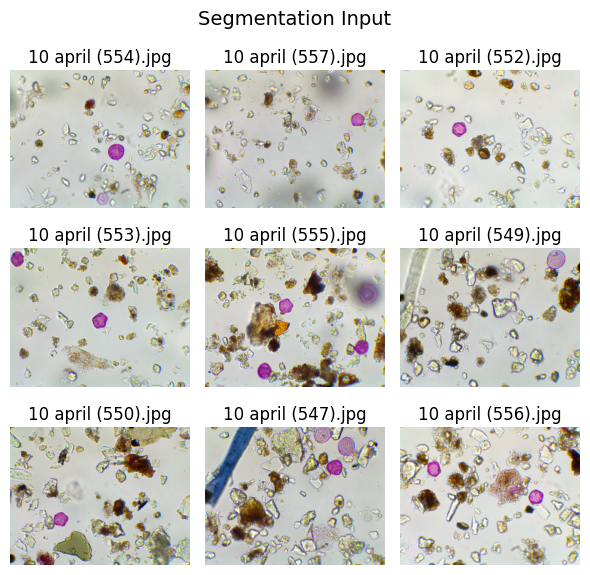

In [49]:
segmentation_input_dir = os.path.join(DatasetPath.real_historical_samples, "april 10")
images = glob(os.path.join(segmentation_input_dir, "*.jpg"))

# Plot some samples
samples = images[0:9]
n = math.ceil(len(samples) ** (1/2))
fig, axs = plt.subplots(nrows=n, ncols=n, figsize=(n*2, n*2))
for ax, img_path in zip(axs.flatten(), samples):
    image_rgb = io.imread(img_path)
    ax.imshow(image_rgb)
    ax.set_axis_off()
    ax.set_title(os.path.basename(img_path))
for ax in axs.flatten()[len(samples):]:
    ax.set_visible(False)
fig.suptitle('Segmentation Input', fontsize=14)
plt.tight_layout()
plt.show()

### Process all images

In [50]:
segmentation_output_dir = "Save/app_pipeline/segmentation_output"

In [51]:
if os.path.exists(segmentation_output_dir):
    shutil.rmtree(segmentation_output_dir)
os.makedirs(segmentation_output_dir, exist_ok=True)

In [52]:
for image_path in tqdm(images):
    segmentation_model(image_path=image_path, output_dir=segmentation_output_dir)

  0%|          | 0/279 [00:00<?, ?it/s]

### Plot some objs

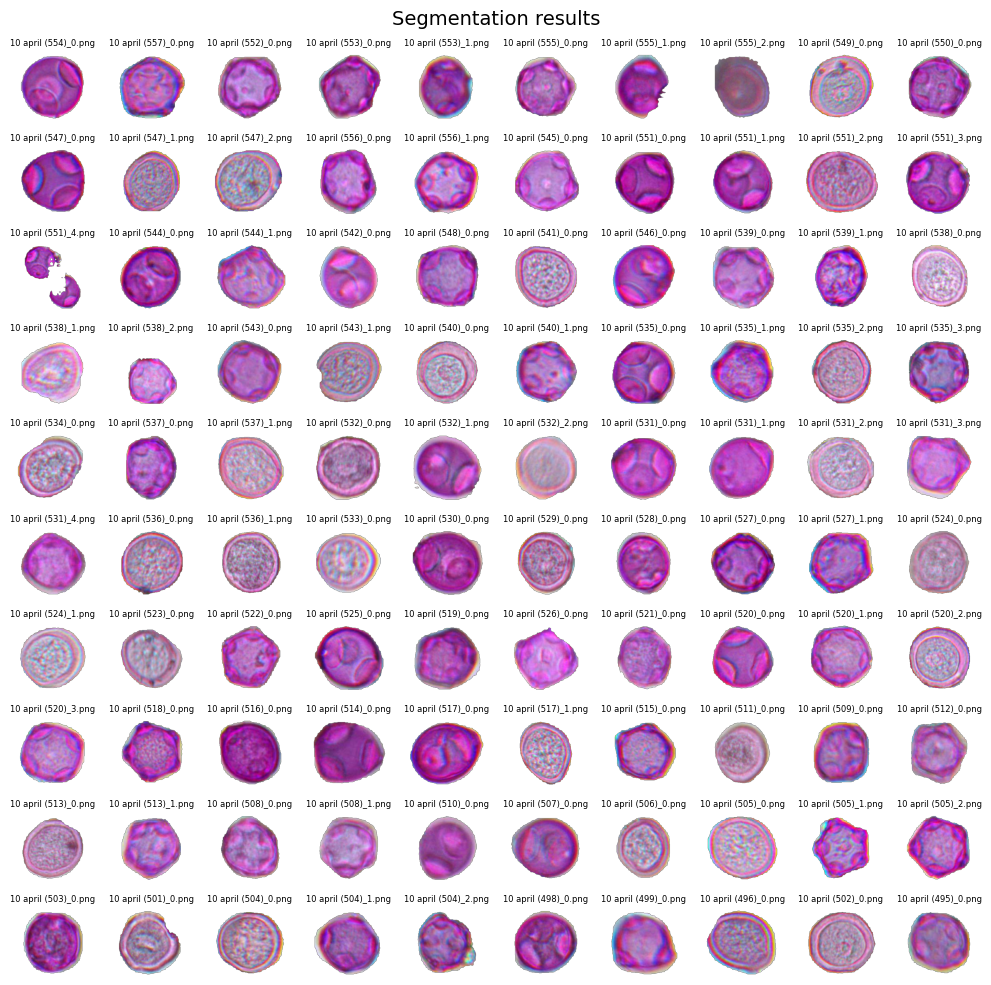

In [10]:

from common.img_utils import clean_background

all_obj_images = glob(os.path.join(segmentation_output_dir,  "**", "*.png"), recursive=True)[0:100]
n = math.ceil(len(all_obj_images) ** (1/2))
fig, axs = plt.subplots(nrows=n, ncols=n, figsize=(n, n))
for ax, img_path in zip(axs.flatten(), all_obj_images):
    image_rgb = io.imread(img_path)
    image_rgb = clean_background(image_rgb)
    ax.imshow(image_rgb)
    ax.set_axis_off()
    ax.set_title(os.path.basename(img_path), fontsize=6)
for ax in axs.flatten()[len(all_obj_images):]:
    ax.set_visible(False)

fig.suptitle('Segmentation results', fontsize=14)
plt.tight_layout()
plt.show()

## OSC Model

In [11]:
from common.osc_classification import OpenSetClassificationModel, extract_features

classification_model = OpenSetClassificationModel(19)
classification_model.load_state_dict(torch.load(ModelPath.osc_classification))
classification_model.to("cuda")


Using cache found in C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


OpenSetClassificationModel(
  (model): DinoVisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
      (norm): Identity()
    )
    (blocks): ModuleList(
      (0-11): 12 x NestedTensorBlock(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): MemEffAttention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (ls1): LayerScale()
        (drop_path1): Identity()
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False

### Fill DB using OSC Model and reference dataset

In [ ]:
from common.configuration import DatasetPath, ModelPath, species_native, species_label_map_all, species_classes_map_all

In [13]:
OBJECTS_ROOT = DatasetPath.reference_images
known_classes = species_native
unknown_classes = species_invasive

### Process real-world samples

In [17]:
def erode(cycles, image):
    for _ in range(cycles):
         image = image.filter(ImageFilter.MinFilter(3))
    return image


def dilate(cycles, image):
    for _ in range(cycles):
         image = image.filter(ImageFilter.MaxFilter(3))
    return image
    
def smooth_edges(img):
    img_gray = img.convert("L")
    threshold = 0
    img_threshold = img_gray.point(
        lambda x: 255 if x > threshold else 0
    )
    step_1 = erode(3, img_threshold)
    mask = erode(1, step_1)
    mask = mask.convert("L")
    mask = mask.filter(ImageFilter.BoxBlur(3))
    blank = img.point(lambda _: 0)
    segmented = Image.composite(img, blank, mask)
    return segmented

In [18]:
from common.osc_classification import distance_to_scores, scores_to_class

In [ ]:
pred_labels = {}
embeddings_data = []
predicted_labels = []

all_obj_images = glob(os.path.join(segmentation_output_dir,  "**", "*.png"), recursive=True)
for img_path in tqdm(all_obj_images):
    img = Image.open(img_path).convert("RGB")
    img = smooth_edges(img)
    features, pred_distances = extract_features(img, classification_model)
    vector = features[0]
    # classification by model
    scores = distance_to_scores(pred_distances)
    prediction = scores_to_class(scores, 8)
    predict_str = [species_label_map_all[l.item()] for l in prediction.cpu()]
    pred_class = predict_str[0]
    if pred_class in pred_labels:
        pred_labels[pred_class] = pred_labels[pred_class] + 1
    else:
        pred_labels[pred_class] = 1
    embeddings_data.append(vector.cpu().numpy())
    predicted_labels.append(prediction.cpu().numpy()[0])

  0%|          | 0/412 [00:00<?, ?it/s]

e:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\common\osc_classification.py:53: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at ..\aten\src\ATen\native\TensorShape.cpp:3641.)
  pred_candidate = torch.where(scores[range(scores.shape[0]), candidate.T] < threshold, candidate, -1)


Plot T-SNE for real-world images

e:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\.venv\lib\site-packages\sklearn\manifold\_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


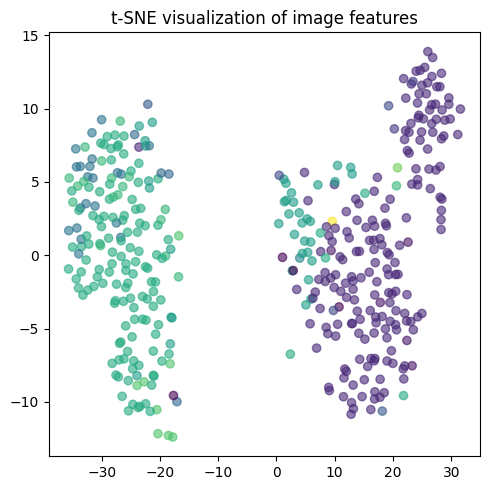

In [21]:
# TSNE
vectors = np.array(embeddings_data)
tsne = TSNE(n_components=2, random_state=42, perplexity=30, metric="euclidean", n_iter=2000, n_jobs=-1, early_exaggeration=12)#cosine
vectors_2d = tsne.fit_transform(vectors)

plt.figure(figsize=(5, 5))
plt.scatter(vectors_2d[:,0], vectors_2d[:,1], c=predicted_labels, alpha=0.6)

plt.title("t-SNE visualization of image features")
plt.tight_layout()
plt.show()

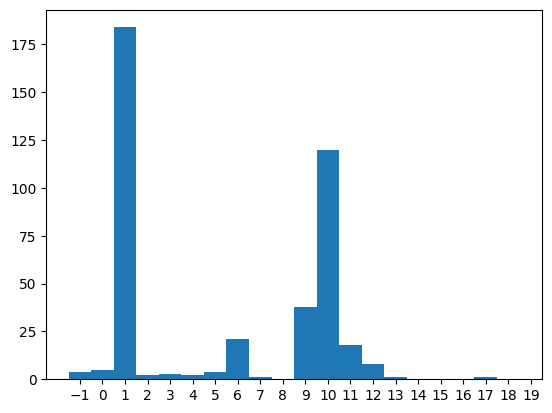

In [ ]:
plt.hist(predicted_labels, bins=np.arange(21)-1,align="left")
plt.xticks(np.arange(21)-1)
plt.show()

In [23]:
pred_labels

{'Betula': 184,
 'Salix': 38,
 'Artemisia': 8,
 'Populus tremula': 120,
 'Poaceae': 21,
 'Pinus': 4,
 'Urtica': 18,
 'Fraxinus': 1,
 'Alnus': 5,
 'Unknown': 4,
 'Acer': 3,
 'Corylus': 2,
 'Apiaceae': 1,
 'Chenopodiaceae': 2,
 'Picea': 1}

### Compare with manual data

In [53]:
excel_path = os.path.join(DatasetPath.real_historical_samples, "manual_analysis.xlsx")
df = pd.ExcelFile(excel_path)

In [54]:
sheet_data = df.parse(df.sheet_names[0])
sheet_data = sheet_data.rename(columns={"Populus": "Populus tremula"})
sheet_data.head(4)

,date,Corylus,Populus tremula,Alnus,Betula,Urtica,Salix,Acer,Ulmus,Pinus,Picea,Tilia,Plantago,Gramineae,Artemisia,Ambrosia,Chenopodiaceae,Unnamed: 17,Unknown
0,april 10,72.0,178.0,150.0,6.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,6.0
1,april 12,30.0,82.0,61.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,3.0
2,april 16,22.0,61.0,50.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,NaN,1.0
3,april 18,57.0,149.0,166.0,13.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,6.0


In [29]:
from common.stats import calculate_confusion_matrix, plot_confusion_matrix

In [27]:
def test_sample_data(true_labels, pred_labels, all_classes):
    print("---Sample test---")
    print(f"True Total objets: {sum(true_labels.values())}, data: {true_labels}")
    print("-" * 10)
    print(f"Pred Total objets: {sum(pred_labels.values())}, data: {pred_labels}")
    confusion_matrices_df = calculate_confusion_matrix(true_labels, pred_labels, all_classes)
    plot_confusion_matrix(confusion_matrices_df.iloc[:, 0:3])
    for k in true_labels.keys():
        if true_labels[k] != 0:
            print(k, round(confusion_matrices_df["TP"].to_dict().get(k, 0) / true_labels[k], 3))

C:\Users\siniz\AppData\Local\Temp\ipykernel_22576\2665805821.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  output_dir = str(sheet_data.iloc[i][0])


  0%|          | 0/412 [00:00<?, ?it/s]

---Sample test---
True Total objets: nan, data: {'Corylus': 72.0, 'Populus tremula': 178.0, 'Alnus': 150.0, 'Betula': 6.0, 'Urtica': 1.0, 'Salix': 0.0, 'Acer': 0.0, 'Ulmus': 0.0, 'Pinus': 0.0, 'Picea': 0.0, 'Tilia': 0.0, 'Plantago': 0.0, 'Gramineae': 0.0, 'Artemisia': 0.0, 'Ambrosia': 0.0, 'Chenopodiaceae': 0.0, 'Unnamed: 17': nan, 'Unknown': 6.0}
----------
Pred Total objets: 412, data: {'Betula': 184, 'Salix': 38, 'Artemisia': 8, 'Populus tremula': 120, 'Poaceae': 21, 'Pinus': 4, 'Urtica': 18, 'Fraxinus': 1, 'Alnus': 5, 'Unknown': 4, 'Acer': 3, 'Corylus': 2, 'Apiaceae': 1, 'Chenopodiaceae': 2, 'Picea': 1}


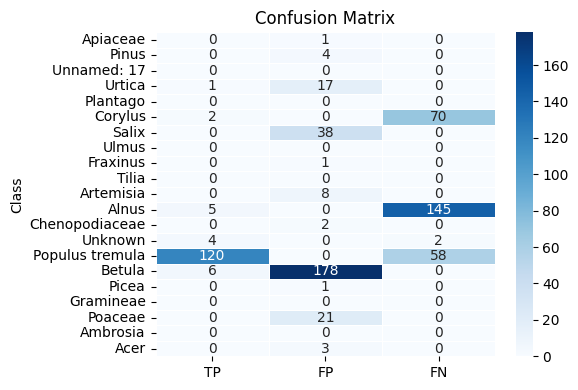

Corylus 0.028
Populus tremula 0.674
Alnus 0.033
Betula 1.0
Urtica 1.0
Unnamed: 17 nan
Unknown 0.667


In [ ]:
for i in range(1):
    output_dir = str(sheet_data.iloc[i][0])
    true_labels = sheet_data.iloc[i][1:].to_dict()
    pred_labels = {}

    all_obj_images = glob(os.path.join(segmentation_output_dir,
                                       output_dir, 
                                       "*.png"), recursive=True)
    for img_path in tqdm(all_obj_images):
        img = Image.open(img_path).convert("RGB")
        img = smooth_edges(img)
        features, pred_distances = extract_features(img, classification_model)
        vector = features[0]
        # classification by model
        scores = distance_to_scores(pred_distances)
        prediction = scores_to_class(scores, 8.0)
        predict_str = [species_label_map_all[l.item()] for l in prediction.cpu()]
        pred_class = predict_str[0]

        if pred_class in pred_labels:
            pred_labels[pred_class] = pred_labels[pred_class] + 1
        else:
            pred_labels[pred_class] = 1
    all_classes = set(true_labels.keys()).union(set(pred_labels.keys()))
    test_sample_data(true_labels, pred_labels, all_classes)